# Análises: Olist E-commerce

Respostas às cinco perguntas escolhidas (uma por tópico do desafio), calculadas a partir da camada **gold** do Data Warehouse (`warehouse/olist.duckdb`).

- **Antes de rodar:** execute o pipeline na raiz do repositório (`python -m src.pipeline`).
- Cada pergunta tem a sua consulta em `sql/analysis/`, as mesmas usadas pelo dashboard: os números são idênticos nos dois.
- As premissas (receita = pedidos entregues, atraso comparado por data, cliente = `customer_unique_id`) estão na seção 6 do README.
- Os gráficos são salvos em `docs/figures/`, e a última célula gera `docs/analysis_report.md`.

In [1]:
import sys
from pathlib import Path

from IPython.display import Markdown, display

# O notebook fica em notebooks/; o código do projeto, em src/ (um nível acima).
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src import charts
from src.analysis import run_query
from src.charts import br

charts.use_style()
report = []  # (tópico, pergunta, figura, conclusão): vira o docs/analysis_report.md no final

## 1. Vendas: como a receita total varia mês a mês?

**Como foi medido:** soma do preço dos itens (sem frete) dos pedidos **entregues**, pelo mês da compra, de jan/2017 a ago/2018, os meses com operação completa (as pontas do dataset têm poucos pedidos e distorceriam a tendência).

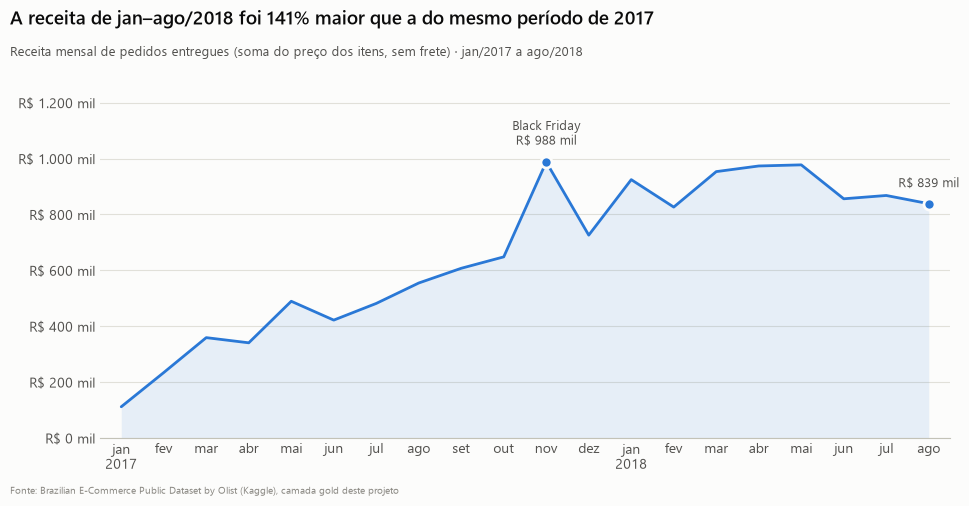

In [2]:
q1 = run_query("q1_monthly_revenue")

jan_aug = q1[q1["month"] <= 8].groupby("year")["revenue"].sum()
growth = jan_aug[2018] / jan_aug[2017] - 1
peak = q1.loc[q1["revenue"].idxmax()]
revenue_2018 = q1.loc[q1["year"] == 2018, "revenue"]

fig = charts.monthly_revenue(
    q1,
    title=f"A receita de jan–ago/2018 foi {br(growth * 100)}% maior que a do mesmo período de 2017",
    subtitle="Receita mensal de pedidos entregues (soma do preço dos itens, sem frete) · jan/2017 a ago/2018",
    peak_note="Black Friday",
)
charts.save_figure(fig, "q1_receita_mensal");

In [3]:
q1.round(2)

,year_month,year,month,revenue,orders,avg_ticket
0,2017-01,2017,1,111798.36,750,149.06
1,2017-02,2017,2,234223.40,1653,141.70
2,2017-03,2017,3,359198.85,2546,141.08
3,2017-04,2017,4,340669.68,2303,147.92
4,2017-05,2017,5,489338.25,3546,138.00
5,2017-06,2017,6,421923.37,3135,134.58
6,2017-07,2017,7,481604.52,3872,124.38
7,2017-08,2017,8,554699.70,4193,132.29
8,2017-09,2017,9,607399.67,4150,146.36
9,2017-10,2017,10,648247.65,4478,144.76


In [4]:
conclusion = (
    f"A receita mais que dobrou: **+{br(growth * 100)}%** em jan–ago/2018 frente ao mesmo período de "
    f"2017 (de R$ {br(jan_aug[2017] / 1e6, 2)} mi para R$ {br(jan_aug[2018] / 1e6, 2)} mi). O pico foi em "
    f"**{charts.month_name(peak['year_month'])}**, mês da Black Friday (R$ {br(peak['revenue'] / 1e3)} mil), "
    f"e em 2018 a receita ficou num patamar de R$ {br(revenue_2018.min() / 1e3)} a "
    f"{br(revenue_2018.max() / 1e3)} mil por mês. **Para o negócio:** novembro exige planejar estoque e "
    "logística com antecedência, e o platô de 2018 indica que o próximo salto depende de novas "
    "alavancas, como recompra e expansão regional."
)
display(Markdown(conclusion))
report.append(
    ("Vendas", "Como a receita total varia mês a mês?", "q1_receita_mensal", conclusion)
)

A receita mais que dobrou: **+141%** em jan–ago/2018 frente ao mesmo período de 2017 (de R$ 2,99 mi para R$ 7,22 mi). O pico foi em **nov/2017**, mês da Black Friday (R$ 988 mil), e em 2018 a receita ficou num patamar de R$ 826 a 978 mil por mês. **Para o negócio:** novembro exige planejar estoque e logística com antecedência, e o platô de 2018 indica que o próximo salto depende de novas alavancas, como recompra e expansão regional.

## 2. Logística: qual o tempo médio de entrega, em dias, por estado?

**Como foi medido:** dias corridos entre a compra e a entrega ao cliente, nos pedidos entregues, pelo estado do endereço de entrega. O marcador mostra o prazo **prometido** médio: demorar não é o mesmo que atrasar.

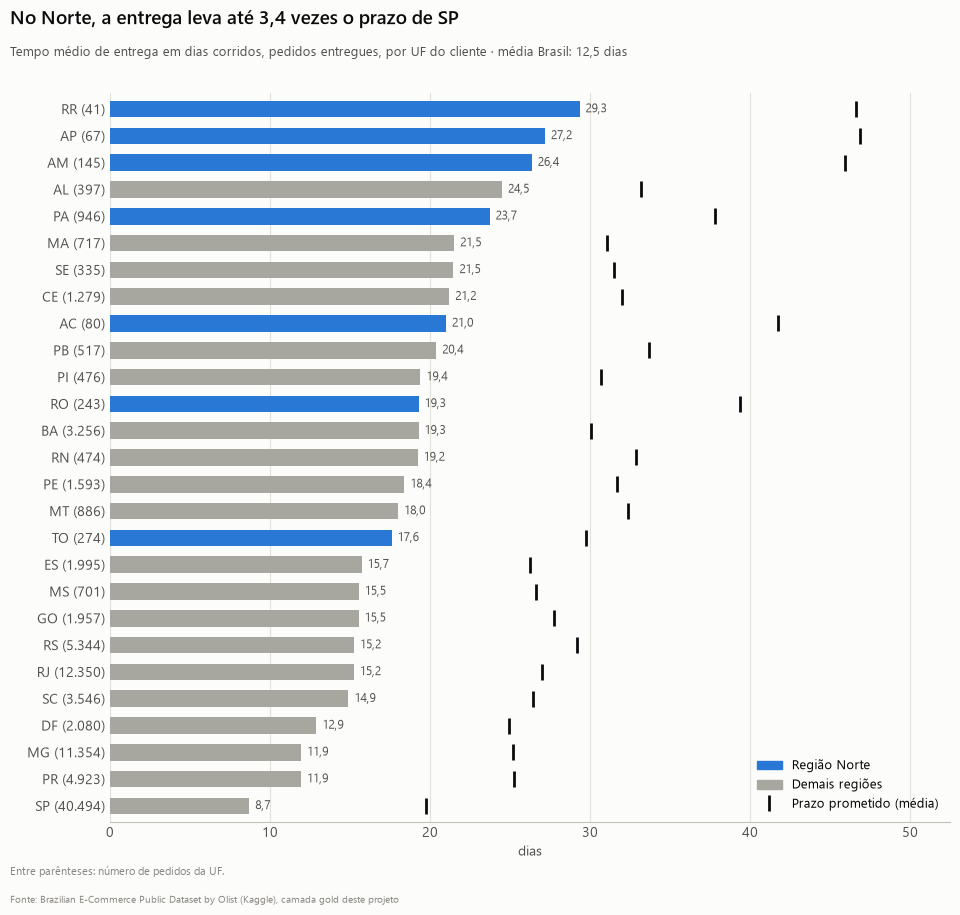

In [5]:
q2 = run_query("q2_delivery_time_by_state")

# Média nacional ponderada pelo número de pedidos de cada UF (média de médias estaria errada).
national = (q2["avg_delivery_days"] * q2["orders"]).sum() / q2["orders"].sum()
delivery = q2.set_index("state")
north = q2[q2["region"] == "Norte"]  # q2 vem ordenada do maior prazo para o menor
ratio = north.iloc[0]["avg_delivery_days"] / delivery.loc["SP", "avg_delivery_days"]

fig = charts.state_bars(
    q2,
    value_col="avg_delivery_days",
    value_label=lambda v: br(v, 1),
    title=f"No Norte, a entrega leva até {br(ratio, 1)} vezes o prazo de SP",
    subtitle=f"Tempo médio de entrega em dias corridos, pedidos entregues, por UF do cliente · média Brasil: {br(national, 1)} dias",
    xlabel="dias",
    marker_col="avg_promised_days",
    marker_name="Prazo prometido (média)",
)
charts.save_figure(fig, "q2_prazo_por_estado");

In [6]:
q2.round(3)

,state,region,orders,avg_delivery_days,median_delivery_days,avg_promised_days,late_share
0,RR,Norte,41,29.341,25.0,46.634,0.122
1,AP,Norte,67,27.179,25.0,46.866,0.030
2,AM,Norte,145,26.359,26.0,45.924,0.028
3,AL,Nordeste,397,24.501,22.0,33.209,0.214
4,PA,Norte,946,23.725,21.0,37.792,0.112
5,MA,Nordeste,717,21.512,19.0,31.084,0.174
6,SE,Nordeste,335,21.463,18.0,31.484,0.152
7,CE,Nordeste,1279,21.200,18.0,32.005,0.138
8,AC,Norte,80,21.000,18.0,41.725,0.038
9,PB,Nordeste,517,20.389,18.0,33.650,0.104


In [7]:
most_late = q2.sort_values("late_share", ascending=False).head(2)
small = q2.loc[q2["orders"] < 150, "state"].tolist()
small_text = (
    ", ".join(small[:-1]) + " e " + small[-1] if len(small) > 1 else "".join(small)
)
late_text = " e ".join(
    f"{row.state} ({row.region}, {br(row.late_share * 100, 1)}%)"
    for row in most_late.itertuples()
)
conclusion = (
    f"O prazo médio no Brasil é de **{br(national, 1)} dias**, mas depende muito da distância: no Norte "
    f"vai de {br(north['avg_delivery_days'].min(), 1)} a {br(north['avg_delivery_days'].max(), 1)} dias, "
    f"contra {br(delivery.loc['SP', 'avg_delivery_days'], 1)} em SP. Mesmo assim, o Norte atrasa pouco "
    f"(AM: {br(delivery.loc['AM', 'late_share'] * 100, 1)}% dos pedidos), porque o prazo prometido já "
    f"embute a distância; os maiores índices de atraso estão em {late_text}. **Para o negócio:** no "
    "Norte, o desafio é encurtar o prazo, não só cumprir a promessa. "
    f"_Ressalva: {small_text} têm menos de 150 pedidos cada; as médias desses estados oscilam mais._"
)
display(Markdown(conclusion))
report.append(
    (
        "Logística",
        "Qual o tempo médio de entrega, em dias, por estado?",
        "q2_prazo_por_estado",
        conclusion,
    )
)

O prazo médio no Brasil é de **12,5 dias**, mas depende muito da distância: no Norte vai de 17,6 a 29,3 dias, contra 8,7 em SP. Mesmo assim, o Norte atrasa pouco (AM: 2,8% dos pedidos), porque o prazo prometido já embute a distância; os maiores índices de atraso estão em AL (Nordeste, 21,4%) e MA (Nordeste, 17,4%). **Para o negócio:** no Norte, o desafio é encurtar o prazo, não só cumprir a promessa. _Ressalva: RR, AP, AM e AC têm menos de 150 pedidos cada; as médias desses estados oscilam mais._

## 3. Satisfação: pedidos atrasados têm nota média menor que os entregues no prazo?

**Como foi medido:** nota da avaliação (1 a 5; uma por pedido, a respondida por último) dos pedidos entregues, comparando quem chegou até o dia prometido com quem chegou depois, e separando os atrasados por faixa de dias.

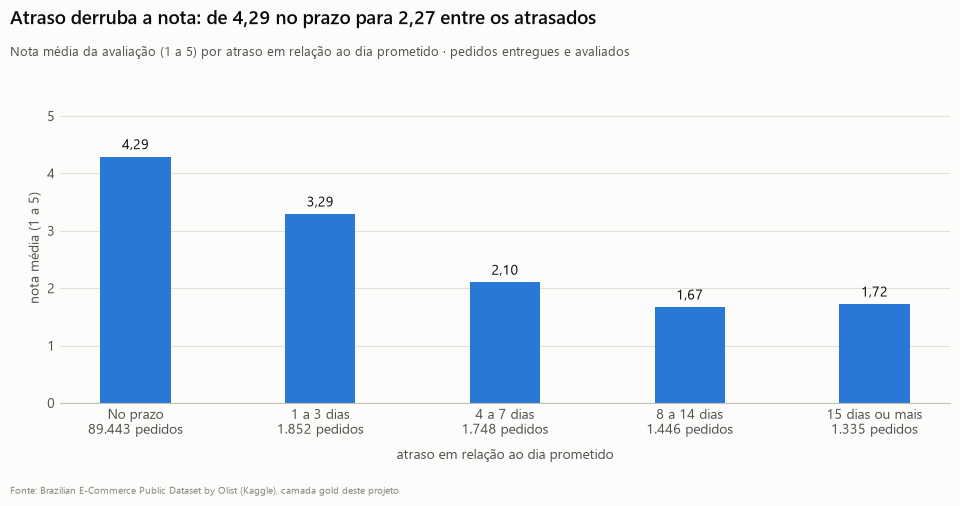

In [8]:
q3 = run_query("q3_review_score_by_delay")


def weighted_mean(rows, column):
    """Média ponderada pelo número de pedidos de cada faixa."""
    return (rows[column] * rows["orders"]).sum() / rows["orders"].sum()


on_time, late = q3[~q3["is_late"]], q3[q3["is_late"]]
score_on_time, score_late = (
    weighted_mean(on_time, "avg_score"),
    weighted_mean(late, "avg_score"),
)

fig = charts.score_by_delay(
    q3,
    title=f"Atraso derruba a nota: de {br(score_on_time, 2)} no prazo para {br(score_late, 2)} entre os atrasados",
    subtitle="Nota média da avaliação (1 a 5) por atraso em relação ao dia prometido · pedidos entregues e avaliados",
)
charts.save_figure(fig, "q3_nota_por_atraso");

In [9]:
q3.round(3)

,delay_bucket,delay_label,is_late,orders,avg_score,share_score_1,share_score_5
0,0,No prazo,False,89443,4.290,0.066,0.623
1,1,1 a 3 dias,True,1852,3.291,0.251,0.332
2,2,4 a 7 dias,True,1748,2.103,0.586,0.141
3,3,8 a 14 dias,True,1446,1.671,0.706,0.068
4,4,15 dias ou mais,True,1335,1.724,0.690,0.072


In [10]:
first_bucket = q3.loc[q3["delay_bucket"] == 1].iloc[0]
conclusion = (
    f"Sim, e a diferença é grande: a nota média cai de **{br(score_on_time, 2)}** (no prazo) para "
    f"**{br(score_late, 2)}** (atrasados), e {br(weighted_mean(late, 'share_score_1') * 100)}% dos pedidos "
    f"atrasados recebem nota 1, contra {br(weighted_mean(on_time, 'share_score_1') * 100)}% dos entregues no "
    f"prazo. A queda começa logo: só 1 a 3 dias de atraso já levam a média a {br(first_bucket['avg_score'], 2)}. "
    "**Para o negócio:** cumprir o prazo prometido é a alavanca mais direta de satisfação, e prometer um "
    "prazo realista ajuda tanto quanto entregar rápido. _Associação observada, não prova de causa._"
)
display(Markdown(conclusion))
report.append(
    (
        "Satisfação",
        "Pedidos atrasados têm nota média menor que os entregues no prazo?",
        "q3_nota_por_atraso",
        conclusion,
    )
)

Sim, e a diferença é grande: a nota média cai de **4,29** (no prazo) para **2,27** (atrasados), e 54% dos pedidos atrasados recebem nota 1, contra 7% dos entregues no prazo. A queda começa logo: só 1 a 3 dias de atraso já levam a média a 3,29. **Para o negócio:** cumprir o prazo prometido é a alavanca mais direta de satisfação, e prometer um prazo realista ajuda tanto quanto entregar rápido. _Associação observada, não prova de causa._

## 4. Financeiro: qual o valor médio do frete por estado do cliente?

**Como foi medido:** frete **por pedido** (soma do frete dos itens) dos pedidos entregues, pelo estado do cliente: é o valor que o cliente paga na compra. A média por item subestimaria os pedidos com vários itens.

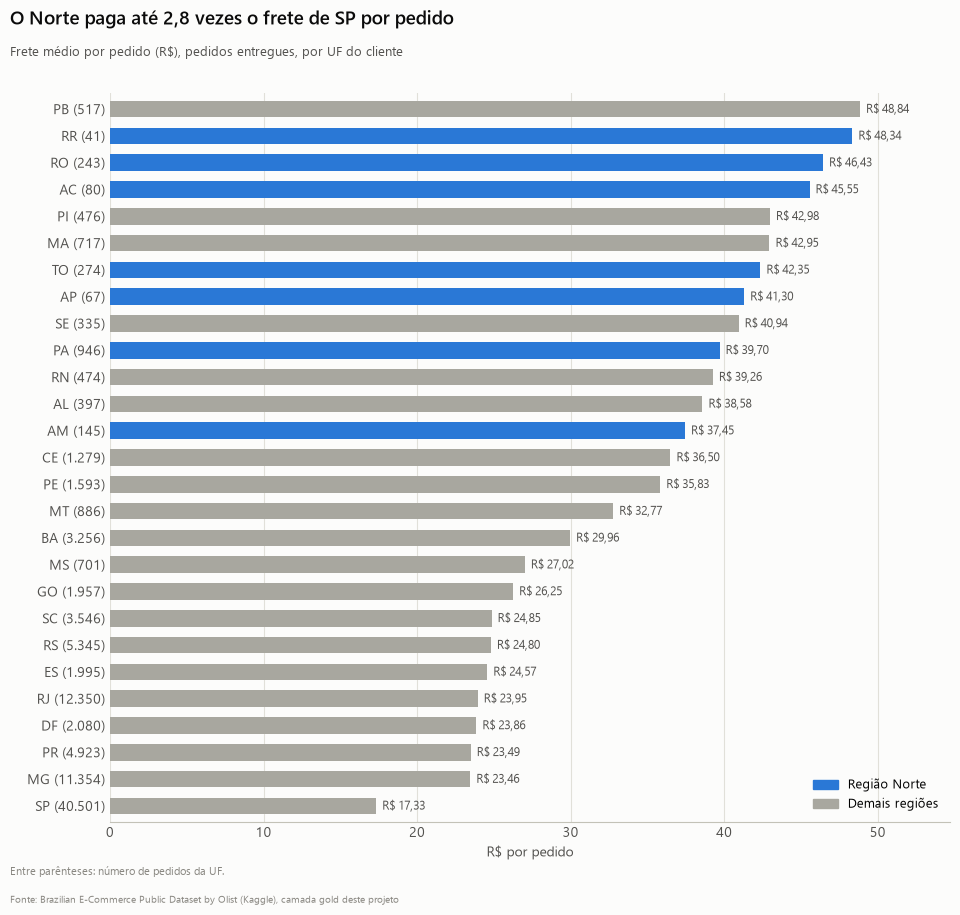

In [11]:
q4 = run_query("q4_freight_by_state")

freight = q4.set_index("state")
# q4 vem ordenada do maior frete para o menor
north_freight = q4[q4["region"] == "Norte"]
north_max, sp = north_freight.iloc[0], freight.loc["SP"]

fig = charts.state_bars(
    q4,
    value_col="avg_freight",
    value_label=lambda v: f"R$ {br(v, 2)}",
    title=f"O Norte paga até {br(north_max['avg_freight'] / sp['avg_freight'], 1)} vezes o frete de SP por pedido",
    subtitle="Frete médio por pedido (R$), pedidos entregues, por UF do cliente",
    xlabel="R$ por pedido",
)
charts.save_figure(fig, "q4_frete_por_estado");

In [12]:
q4.round(3)

,state,region,orders,avg_freight,freight_share_of_items
0,PB,Nordeste,517,48.843,0.224
1,RR,Norte,41,48.343,0.281
2,RO,Norte,243,46.433,0.247
3,AC,Norte,80,45.554,0.229
4,PI,Nordeste,476,42.977,0.241
5,MA,Nordeste,717,42.949,0.263
6,TO,Norte,274,42.354,0.240
7,AP,Norte,67,41.299,0.207
8,SE,Nordeste,335,40.940,0.242
9,PA,Norte,946,39.697,0.215


In [13]:
top = q4.iloc[0]
conclusion = (
    f"O frete médio por pedido vai de **R$ {br(sp['avg_freight'], 2)}** em SP a **R$ {br(top['avg_freight'], 2)}** "
    f"em {top['state']}; no Norte, chega a R$ {br(north_max['avg_freight'], 2)} ({north_max['state']}) e "
    f"equivale a {br(north_max['freight_share_of_items'] * 100)}% do valor dos produtos, contra "
    f"{br(sp['freight_share_of_items'] * 100)}% em SP. As regiões que mais esperam pela entrega (pergunta 2) "
    "são as que mais pagam frete. **Para o negócio:** prazo e frete são as duas barreiras de compra no Norte "
    "e no Nordeste, onde uma operação com estoque perto do cliente tem vantagem."
)
display(Markdown(conclusion))
report.append(
    (
        "Financeiro",
        "Qual o valor médio do frete por estado do cliente?",
        "q4_frete_por_estado",
        conclusion,
    )
)

O frete médio por pedido vai de **R$ 17,33** em SP a **R$ 48,84** em PB; no Norte, chega a R$ 48,34 (RR) e equivale a 28% do valor dos produtos, contra 14% em SP. As regiões que mais esperam pela entrega (pergunta 2) são as que mais pagam frete. **Para o negócio:** prazo e frete são as duas barreiras de compra no Norte e no Nordeste, onde uma operação com estoque perto do cliente tem vantagem.

## 5. Clientes: qual a porcentagem de clientes que compraram mais de uma vez?

**Como foi medido:** clientes únicos (`customer_unique_id`) com pelo menos um pedido entregue, pelo número de compras. O `customer_id` não serve aqui: ele muda a cada pedido.

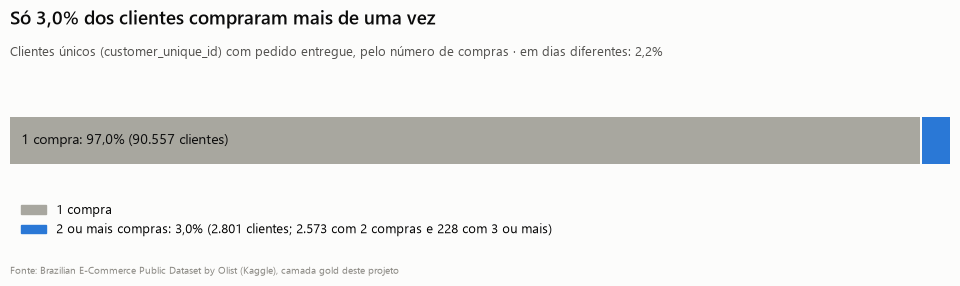

In [14]:
q5 = run_query("q5_repeat_customers")

total = q5["customers"].sum()
repeat = total - q5.loc[q5["purchases"] == "1", "customers"].sum()
repeat_days = q5["customers_on_2plus_days"].sum()

fig = charts.repeat_customers(
    q5,
    title=f"Só {br(repeat / total * 100, 1)}% dos clientes compraram mais de uma vez",
    subtitle=f"Clientes únicos (customer_unique_id) com pedido entregue, pelo número de compras · em dias diferentes: {br(repeat_days / total * 100, 1)}%",
)
charts.save_figure(fig, "q5_recompra");

In [15]:
q5

,purchases,customers,customers_on_2plus_days
0,1,90557,0
1,2,2573,1809
2,3,181,161
3,4+,47,45


In [16]:
conclusion = (
    f"Apenas **{br(repeat / total * 100, 1)}%** dos {br(total)} clientes compraram mais de uma vez "
    f"({br(repeat)} clientes); contando só compras em dias diferentes, a recompra cai para "
    f"{br(repeat_days / total * 100, 1)}%. A base é quase toda de compradores únicos: há espaço claro para "
    "retenção (CRM, cupom de segunda compra), começando pela experiência de entrega, que pesa na "
    "satisfação (pergunta 3). _Com `customer_id` no lugar de `customer_unique_id`, a recompra daria 0%, "
    "porque esse identificador muda a cada pedido._"
)
display(Markdown(conclusion))
report.append(
    (
        "Clientes",
        "Qual a porcentagem de clientes que compraram mais de uma vez?",
        "q5_recompra",
        conclusion,
    )
)

Apenas **3,0%** dos 93.358 clientes compraram mais de uma vez (2.801 clientes); contando só compras em dias diferentes, a recompra cai para 2,2%. A base é quase toda de compradores únicos: há espaço claro para retenção (CRM, cupom de segunda compra), começando pela experiência de entrega, que pesa na satisfação (pergunta 3). _Com `customer_id` no lugar de `customer_unique_id`, a recompra daria 0%, porque esse identificador muda a cada pedido._

## Relatório em Markdown

Junta perguntas, gráficos e conclusões em `docs/analysis_report.md`, para leitura rápida no GitHub. Os textos saem das mesmas variáveis usadas acima, então os números são os mesmos.

In [17]:
lines = [
    "# Relatório de análises",
    "",
    (
        "> Gerado automaticamente pelo notebook [`notebooks/analysis.ipynb`](../notebooks/analysis.ipynb) "
        "a partir da camada gold. As premissas estão na seção 6 do [README](../README.md)."
    ),
    "",
]
for number, (topic, question, figure, text) in enumerate(report, start=1):
    lines += [
        f"## {number}. {topic}: {question}",
        "",
        f"![{question}](figures/{figure}.png)",
        "",
        text,
        "",
    ]

report_path = ROOT / "docs" / "analysis_report.md"
report_path.write_text("\n".join(lines), encoding="utf-8", newline="\n")
print(f"docs/analysis_report.md gerado com {len(report)} análises")

docs/analysis_report.md gerado com 5 análises
